# Week 9 · Putting the system together

You have built every part of the system. This week you see how the parts fit together, put all your decisions in one place, and start your Final project.

| | |
|---|---|
| **This week's question** | How do the parts of a system fit together, and where should your decisions live? |
| **Python you will learn** | modules, `import`, `if __name__ == "__main__":`; running a `.py` file with `subprocess.run` (you read and run these cells; you do not need to write them). No other new syntax. |
| **Principle 9** | **Separate what changes from what stays.** Keep decisions (settings, rules) apart from machinery (storage, screens). |
| **Part you build** | your own system: `fr.System(MY_SETTINGS, hooks=...)`, checked with `verify()`, and Level 1 of the Final project |

*Campus Food Rescue is fictional. All organisations, people and numbers are invented.*

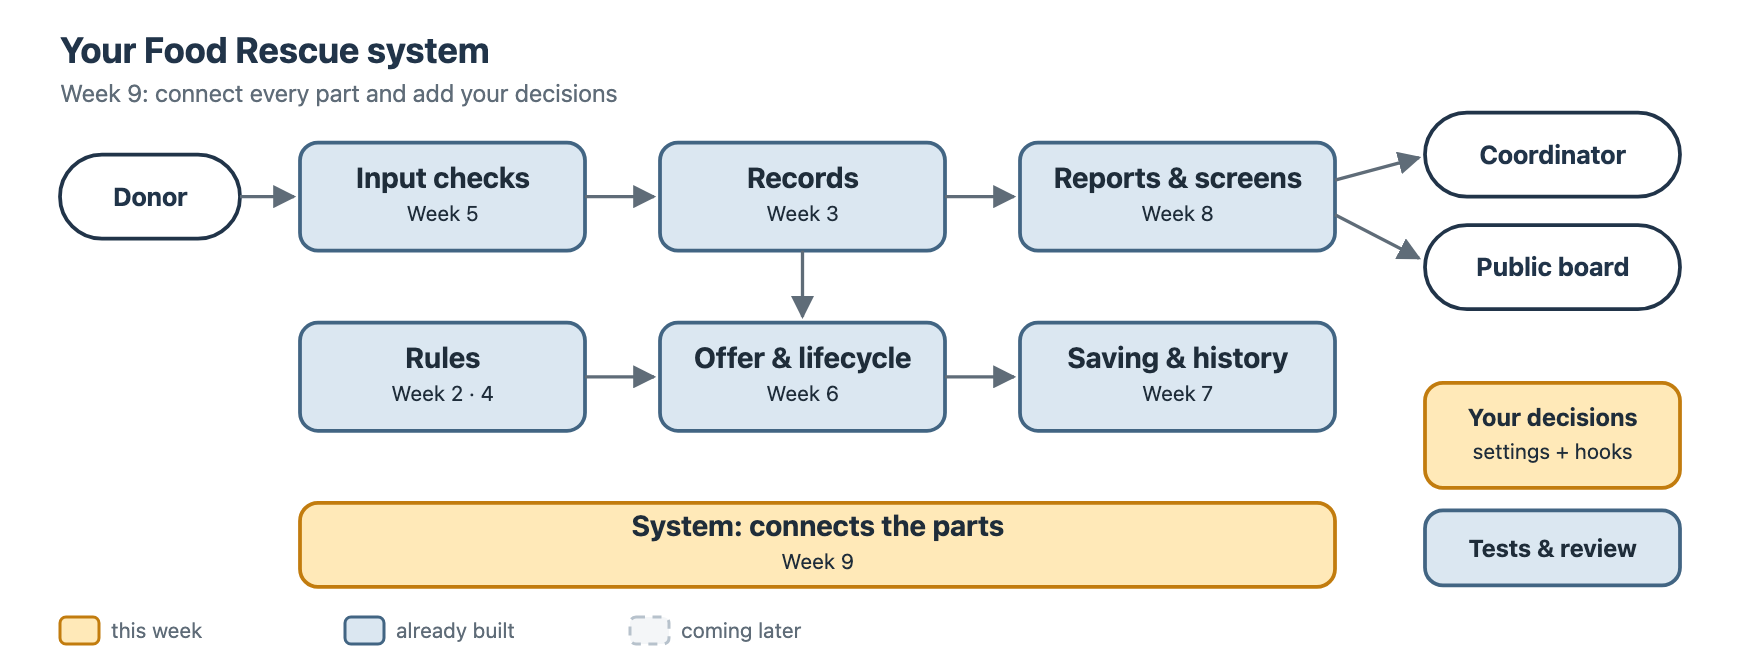

## Before you start

1. **File → Save a copy in Drive**, then work in your copy.
2. Run the setup cell. Run it again after a runtime restart.
3. ⭐ = core for everyone, ⭐⭐ = optional stretch.

In [ ]:
# @title ▶ Run this cell first (setup) — it prepares the Food Rescue system
# It unpacks the course system that is stored inside this notebook.
# No internet, no installation. Run it again after Colab restarts.
import base64, hashlib, importlib, io, os, sys, zipfile
_KIT_VERSION = "2026.11.2"
_KIT_SHA = "87d59ca87437a3c6cc62441c2e95bfb0b252ea6b51ab2ccb7b2875f022775c3a"
_KIT_ZIP = "..."

def _prepare_kit():
    data = base64.b64decode(_KIT_ZIP)
    if hashlib.sha256(data).hexdigest() != _KIT_SHA:
        raise RuntimeError("This notebook's course files are damaged. Download a fresh copy.")
    marker = os.path.join("food_rescue_kit", ".kit_version")
    current = open(marker).read().strip() if os.path.exists(marker) else ""
    keep = ("food_rescue_kit/my_settings.py", "food_rescue_kit/my_rules.py")
    with zipfile.ZipFile(io.BytesIO(data)) as archive:
        for name in archive.namelist():
            if current == _KIT_VERSION and os.path.exists(name):
                continue                      # already up to date
            if name in keep and os.path.exists(name):
                continue                      # never overwrite your own files
            os.makedirs(os.path.dirname(name), exist_ok=True)
            with open(name, "wb") as target:
                target.write(archive.read(name))
    with open(marker, "w") as file:
        file.write(_KIT_VERSION)
    folder = os.path.abspath("food_rescue_kit")
    if folder not in sys.path:
        sys.path.insert(0, folder)
    for module in [m for m in sys.modules if m == "rescue" or m.startswith("rescue.")]:
        del sys.modules[module]             # load the fresh copy

_prepare_kit()
import rescue as fr
print("✅ Food Rescue system ready (version " + fr.KIT_VERSION + "). You can continue.")


## Session 1 · Learn: parts, modules and programs (30 min)

### The idea: what changes and what stays

Think of your phone. You change the ringtone, the language and the screen brightness many times. You do this in **Settings**. You never open the phone to rewire it. The engineers kept the things people decide apart from the machinery (the screen, the battery, the radio). So a change is small and safe, and it cannot break the phone.

Our system works the same way. The **machinery** (checking input, keeping records, saving, showing screens) stays the same. Your **decisions** (the team minimum, the public fields, your own rules) change. They live in two places only: **settings** and **hooks**.

### 1 · A module is a `.py` file

A **module** is a Python file with functions and values inside. `import` loads it. Then `module.name` means *"the name inside that module"*. The dot keeps names from different modules apart.

`math` comes with Python. The Food Rescue system is also made of modules. Since Week 1 the setup cell has run `import rescue as fr`. The word `as` gives the module a short name.

🤔 **Predict** what `fr.rules.pickup_label(30, False)` prints, then run the cell.

In [ ]:
import math
print(math.sqrt(49))
print(math.pi)

import rescue as fr
print(fr.rules.pickup_label(30, True))
print(fr.rules.pickup_label(30, False))
print(fr.records.total_portions(fr.sample_records()))

**Prediction:** …  **Result:** …  **Why:** …

### 2 · The map of the parts

Each part you built lives in its own module. The kit's `README.md` has a map. Every module also starts with a short description, called its **docstring**. Python keeps it in `__doc__`, and the module's own name in `__name__`. Run the cell to read both.

In [ ]:
with open("food_rescue_kit/README.md") as file:
    readme = file.read()

start = readme.find("## Map of the parts")   # the position where the map starts
print(readme[start:])                       # [start:] means: from there to the end

for module in [fr.rules, fr.records, fr.validation, fr.models, fr.storage, fr.reports]:
    first_line = module.__doc__.splitlines()[0]
    print(module.__name__, "·", first_line)

🤔 A coordinator says: *"The saved file got damaged when the laptop switched off."* Which module would you open first? Which module would you open if the public board showed the wrong columns?

**My answer:** …

### 3 · Two places for your decisions: settings and hooks

`fr.DEFAULTS` holds every **setting** with its default value. You change a setting by putting the same name in `MY_SETTINGS`. You never edit the kit's files. `fr.HOOKS` lists the functions you may replace with your own, and how many inputs each one takes.

In [ ]:
print(len(fr.DEFAULTS), "settings")
for name in fr.DEFAULTS:
    print(f"{name:28} {fr.DEFAULTS[name]}")
print()
print(fr.HOOKS)

🤔 Which hook did you write in Week 2? Which one in Week 8? How many inputs does `can_move` take, and what are they?

**My answer:** …

### 4 · How `System` connects the parts

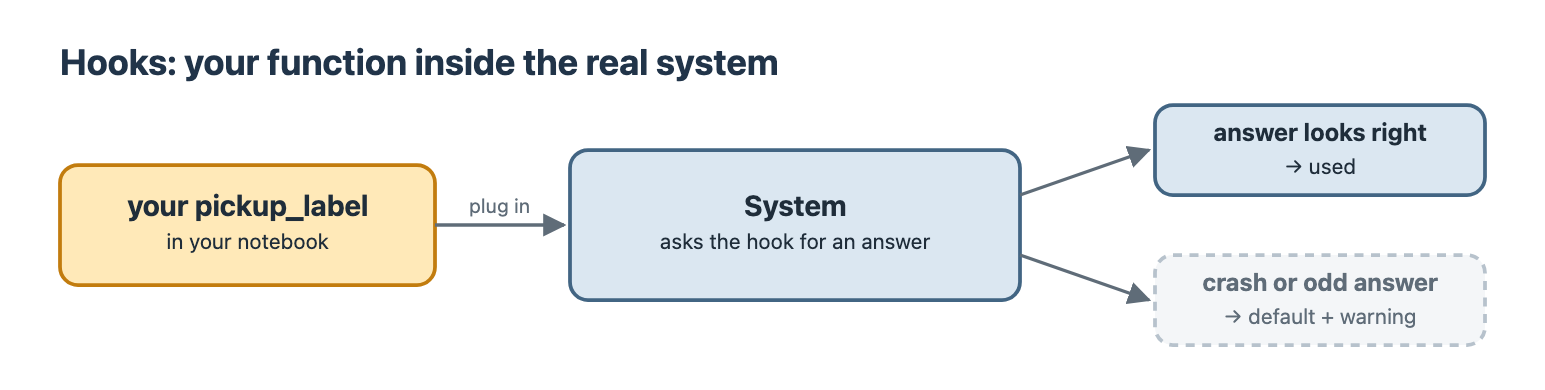

`fr.System(MY_SETTINGS, hooks=...)` does three jobs:

1. It builds **complete settings**: the defaults plus your changes. A misspelt name is ignored with a ⚠️ warning.
2. It prepares one **default function** for each hook, then plugs in yours.
3. Every time it needs an answer, it **asks the hook**. If your function crashes or gives an odd answer, the system says why (once) and uses the default, so the day continues.

🤔 This system has a misspelt setting and a hook that shouts. **Predict** the pickup labels, then run.

In [ ]:
def shouting_label(portions, approved):
    return "TEAM!"            # not one of "hold", "team" or "standard"

test_system = fr.System({"TEAM_PICKUP_MIN_PORTION": 25}, hooks={"pickup_label": shouting_label})
test_system.run_day(show=False)
for offer_id in ["F001", "F004"]:
    offer = test_system.get(offer_id)
    print(offer_id, offer.portions, "portions →", test_system.label(offer))

**Prediction:** …  **Result:** …  **Why:** …

The system never stopped. It refused the bad setting and the bad answer, said why in plain words, and kept the team minimum at 20. That is safe failure. It is also a warning for you: if you do not read the ⚠️ lines, you may think your function is working when it is not.

### 5 · Running a `.py` file in a fresh process

A notebook remembers everything you ran. A real program starts **fresh**: it knows only what is in its own file. Python's `subprocess` module can start a fresh Python and run a file, the same way a terminal does.

In [ ]:
import subprocess
import sys

with open("hello.py", "w") as file:
    file.write('print("Hello from hello.py")\n')
    file.write("print(2 + 3)\n")

result = subprocess.run([sys.executable, "hello.py"], capture_output=True, text=True)
print("It printed:")
print(result.stdout)
print("Return code:", result.returncode)

- `sys.executable` is the Python that runs this notebook. We ask it to run `hello.py`.
- `capture_output=True` collects what the program prints. `text=True` gives it to us as text.
- `result.stdout` is the normal output. `result.stderr` holds error messages. A return code of `0` means *no error*.

🤔 The notebook knows `secret` below. Does the fresh process know it? **Predict**, then run.

In [ ]:
secret = "only in this notebook"

with open("ask.py", "w") as file:
    file.write("print(secret)\n")

result = subprocess.run([sys.executable, "ask.py"], capture_output=True, text=True)
print("Return code:", result.returncode)
print("Last line of the error:", result.stderr.splitlines()[-1])

**Prediction:** …  **Result:** …  **Why:** …

A fresh process is honest: if your program needs something, it must be in the program. Next week you will use this idea to check that your whole notebook runs from a clean start.

### 6 · Importing a file or running it: `if __name__ == "__main__":`

Python gives every module a `__name__`. When you **run** a file, its `__name__` is `"__main__"`. When another file **imports** it, its `__name__` is its module name. The notebook itself is also run, so its `__name__` is `"__main__"` too (see the first line of the cell).

The line `if __name__ == "__main__":` means *"only do this when I am run, not when I am imported"*. It lets one file be both a **program** and a **module**. Here `shop.py` has a useful function and a small demo. `main.py` imports `shop` to use the function.

In [ ]:
print("This notebook says: my __name__ is", __name__)

shop_code = '''
TAX_RATE = 0.10

def price_with_tax(price):
    return round(price * (1 + TAX_RATE), 2)

print("shop.py says: my __name__ is", __name__)

if __name__ == "__main__":
    print("Demo: 100 with tax is", price_with_tax(100))
'''

main_code = '''
import shop

print("main.py says: my __name__ is", __name__)
print("main.py uses shop:", shop.price_with_tax(50))
'''

with open("shop.py", "w") as file:
    file.write(shop_code)
with open("main.py", "w") as file:
    file.write(main_code)

print(subprocess.run([sys.executable, "shop.py"], capture_output=True, text=True).stdout)

🤔 Now run `main.py`. It imports `shop`. **Predict** which lines appear. Does the demo line appear?

In [ ]:
print(subprocess.run([sys.executable, "main.py"], capture_output=True, text=True).stdout)

**Prediction:** …  **Result:** …  **Why:** …

The kit's programs use the same guard. The last lines of `run_web.py` are:

```python
if __name__ == "__main__":
    main()
```

Because of the guard, another file can import `run_web` without starting a web server by accident.

### 7 · Run the kit's own tests in a fresh process

The kit has its own tests in `food_rescue_kit/tests/`. `run_tests.py` runs them all. We run it in a fresh process, from inside the kit folder (`cwd=` means *"start in this folder"*).

In [ ]:
kit_tests = subprocess.run([sys.executable, "run_tests.py"], cwd="food_rescue_kit",
                           capture_output=True, text=True)
lines = kit_tests.stdout.splitlines()
for line in lines:
    if "test_" in line and (line.startswith("✅") or line.startswith("❌")):
        print(line)
print(lines[-1])                           # the last line counts passed and failed tests

🤔 These tests use the **default** settings. Will they still pass after you change `TEAM_PICKUP_MIN_PORTIONS` in your own `MY_SETTINGS`? Why?

**My answer:** …

## Session 2 · Practise and judge (60 min)

### ⭐ P1 · Where does this decision live?

The coordinator sends four requests. Each one is a **decision**, so each one is a setting. Write one line per request in `CHANGES`. Use the names in `fr.DEFAULTS` (Session 1, part 3).

1. *"From now on, send a team from 25 portions."*
2. *"Donors may offer up to 300 portions."*
3. *"Show the hours left on the public board, so partners can plan."*
4. *"Sunflower Youth Club joins as a new partner."* (Keep the three old partners.)

In [ ]:
CHANGES = {
    # TODO: one line per request, for example  "SOME_SETTING": value,
}

In [ ]:
print("✅" if len(CHANGES) == 4 else "❌", len(CHANGES), "of 4 requests written")
for name in CHANGES:
    print("✅" if name in fr.DEFAULTS else "❌", name)

changed_system = fr.System(CHANGES)
changed_system.run_day(show=False)
print(changed_system.report("public"))

🤔 How many lines of the kit's machinery did you change? A fifth request says: *"Send a text message to the partner when food is picked up."* Is that a setting, or new machinery? Why?

**My answer:** …

<details><summary>Show a possible answer</summary>

```python
CHANGES = {
    "TEAM_PICKUP_MIN_PORTIONS": 25,
    "MAX_PORTIONS": 300,
    "PUBLIC_FIELDS": ["id", "food", "category", "portions", "hours_left", "status"],
    "PARTNERS": fr.DEFAULTS["PARTNERS"] + ["Sunflower Youth Club"],
}
```

You changed **zero** lines of machinery. All four requests were values, so they were settings. The text message is different: it is a new job (a new part that talks to a phone service). A setting can only change a decision that the machinery already knows how to apply.

</details>

### ⭐ P2 · Read the machinery

Here is a short part of `system.py` (shortened a little). Read it and answer the questions. You do not need to write code like this; you only need to read it.

```python
def label(self, offer):
    approved = offer.status != "new" or not self.settings["REQUIRE_APPROVAL"]
    return self._call("pickup_label", offer.portions, approved)

def _call(self, name, *args):                 # *args = all the inputs, passed on
    function, default = self.hooks[name], self.defaults[name]
    try:
        result = function(*args)
        problem = result_problem(name, result)   # None when the answer looks right
    except Exception as error:
        problem = "it raised " + type(error).__name__ + ": " + str(error)
    if problem is None:
        return result
    if name not in self.fallbacks:
        print("⚠️ Your " + name + " did not work: " + problem)
    self.fallbacks.setdefault(name, problem)   # remember the first problem
    return default(*args)
```

1. `label` works out `approved` itself. What is `approved` for an offer with status `"new"`? What is it when `REQUIRE_APPROVAL` is `False`?
2. Name the **two kinds** of problem that make `_call` use the default rule.
3. Your hook fails for **two** different offers. How many ⚠️ warnings do you see? Where is the problem remembered?
4. Look for a number such as 20 or 3 in the excerpt. Why is there none?

📝 **My answers:**

1.
2.
3.
4.

Now test your answer to question 3. This hook uses capital letters, so it fails for every offer.

In [ ]:
def capital_label(portions, approved):
    if not approved:
        return "Hold"
    if portions >= 20:
        return "Team"
    return "Standard"

capital_system = fr.System(hooks={"pickup_label": capital_label})
capital_system.run_day(show=False)
for offer_id in ["F001", "F004"]:
    offer = capital_system.get(offer_id)
    print(offer_id, offer.portions, "portions →", capital_system.label(offer))
print("Remembered:", capital_system.fallbacks)

<details><summary>Show a possible answer</summary>

1. For a `"new"` offer, `approved` is `False` (so the label is `"hold"`). When `REQUIRE_APPROVAL` is `False`, `not self.settings["REQUIRE_APPROVAL"]` is `True`, so `approved` is always `True`.
2. Your function **raised an error** (`except`), or it **returned an answer with the wrong shape** (`result_problem` found a problem, for example `"Team"` or `None`).
3. **One** warning, the first time (`if name not in self.fallbacks`). The problem is remembered in `self.fallbacks`. One clear message is better than a screen full of the same message, but it is easy to miss. Always read the ⚠️ lines.
4. The machinery holds **no decisions**. The numbers come from settings, and the rules come from hooks. That is Principle 9.

</details>

### ⭐ P3 · Add the guard

`counter.py` has a useful function and a demo line. `report.py` imports it. Right now the demo also runs when `report.py` imports `counter`, which is noise in someone else's program. Put the demo line under `if __name__ == "__main__":` (indent it by 4 spaces). Then run the check cell.

In [ ]:
counter_code = '''
def count_words(text):
    return len(text.split())

print("Demo:", count_words("bread rolls from Sunrise Bakery"))
'''

In [ ]:
report_code = '''
import counter
print("Report:", counter.count_words("rice meals for the Riverside Community Kitchen"))
'''
with open("counter.py", "w") as file:
    file.write(counter_code)
with open("report.py", "w") as file:
    file.write(report_code)

run_directly = subprocess.run([sys.executable, "counter.py"], capture_output=True, text=True)
imported = subprocess.run([sys.executable, "report.py"], capture_output=True, text=True)
print("Running counter.py:", run_directly.stdout, run_directly.stderr)
print("Running report.py:", imported.stdout, imported.stderr)
print("✅" if "Demo" in run_directly.stdout else "❌", "the demo runs when you run counter.py")
print("✅" if "Demo" not in imported.stdout else "❌", "the demo stays quiet when report.py imports counter")

<details><summary>Show a possible answer</summary>

```python
def count_words(text):
    return len(text.split())

if __name__ == "__main__":
    print("Demo:", count_words("bread rolls from Sunrise Bakery"))
```

If you see `IndentationError` in the output, the demo line is not indented by exactly 4 spaces under the `if`.

</details>

### ⭐⭐ S1 · Your first program file

Write a small program `daily_summary.py` that imports `rescue`, replays the sample day silently and prints `summary_text()`. Put the work inside a function `main()` and call it under the guard. The cell saves it inside the kit folder, so `import rescue as fr` works there.

In [ ]:
program_code = '''
# TODO: import rescue as fr, define main(), and call main() under the guard
'''

with open("food_rescue_kit/daily_summary.py", "w") as file:
    file.write(program_code)
summary_run = subprocess.run([sys.executable, "daily_summary.py"], cwd="food_rescue_kit",
                             capture_output=True, text=True)
print(summary_run.stdout, summary_run.stderr)

### ⚖️ Good or risky?

You asked an AI assistant: *"Add a team column to the coordinator report. And make sure the public web page never shows contact details."* It wrote **Version A**. **Version B** is a rewrite. Both run.

**Version A**

```python
def report_line(record):
    if record["portions"] >= 20:
        team = "team"
    else:
        team = "standard"
    return f"{record['id']} {record['food']} · {team}"

def web_public_row(record):
    row = dict(record)
    del row["contact"]
    return row
```

**Version B**

```python
def report_line(system, offer):
    return f"{offer.id} {offer.food} · {system.label(offer)}"

def web_public_row(system, record):
    return fr.reports.public_row(record, system.settings["PUBLIC_FIELDS"])
```

Use **Principle 9 (separate what changes from what stays)**. Find **at least three** problems in Version A. For each one, say which offer or person would be harmed.

📝 **Problems I found in Version A:**

1.
2.
3.

<details><summary>Instructor's view</summary>

1. **A decision buried in report code.** The 20 is the coordinator's team minimum, but it is copied into the report. If the coordinator changes `TEAM_PICKUP_MIN_PORTIONS` to 15 because many volunteers are elderly, this report still says "standard" for 18 portions of rice. One volunteer carries everything alone, and the report disagrees with the rest of the system.
2. **The approval rule is ignored.** The real rule says a new offer is `"hold"`. Version A says "team" for a new, unapproved offer, and even for the rejected bananas (F003, 40 portions). Volunteers could drive to the Green Market Stall for food the coordinator refused.
3. **A privacy rule buried in screen code.** The page hides only `contact`. It still shows the donor's name, the partner and the hours left. A donor such as Lotus Cafe may not want to be named in public. If someone adds a new private field later (say, a phone number), it appears on the public page at once.
4. **Fragile.** `del row["contact"]` crashes with `KeyError` for a record that has no contact.

Version B **asks the system**. The label comes from the one pickup rule (your hook, your setting, the approval rule). The public row comes from `PUBLIC_FIELDS`, a list of what *may* be shown. Change the setting and every screen follows. AI assistants often copy a rule into the place where they need it. Your job is to notice the copy and point it back to the one place where the decision lives.

</details>

### ⭐ P4 · Repair: move the decisions into settings

The AI also wrote `web_row` for the web page. It runs, but two decisions are buried inside it. Change it so that:

- the urgent badge uses `settings["URGENT_HOURS"]` instead of `3`;
- only the fields in `settings["PUBLIC_FIELDS"]` are shown, in that order.

The check cell below tries **two different settings**. Code that follows the settings passes both.

In [ ]:
def web_row(record, settings):
    # Written by an AI assistant. Two decisions are buried in here.
    if record["hours_left"] <= 3:
        badge = "URGENT"
    else:
        badge = ""
    shown = {}
    for field in record:
        if field != "contact":
            shown[field] = record[field]
    return badge, shown

In [ ]:
record = fr.sample_records()[3]            # F004: 4 hours left
strict = {"URGENT_HOURS": 3, "PUBLIC_FIELDS": ["id", "food", "status"]}
relaxed = {"URGENT_HOURS": 6, "PUBLIC_FIELDS": ["id", "food", "portions", "status"]}

badge, shown = web_row(record, strict)
print("✅" if badge == "" else "❌", "URGENT_HOURS 3: 4 hours left is not urgent →", repr(badge))
print("✅" if list(shown) == strict["PUBLIC_FIELDS"] else "❌", "only PUBLIC_FIELDS →", list(shown))
badge, shown = web_row(record, relaxed)
print("✅" if badge == "URGENT" else "❌", "URGENT_HOURS 6: 4 hours left is urgent →", repr(badge))
print("✅" if list(shown) == relaxed["PUBLIC_FIELDS"] else "❌", "the board follows the setting →", list(shown))

<details><summary>Show a possible answer</summary>

```python
def web_row(record, settings):
    if record["hours_left"] <= settings["URGENT_HOURS"]:
        badge = "URGENT"
    else:
        badge = ""
    shown = {}
    for field in settings["PUBLIC_FIELDS"]:
        shown[field] = record.get(field, "")
    return badge, shown
```

Two ideas matter. Read the number from the setting, so there is one place to change it. And list what **may** be shown, not what must be hidden: a new private field is then safe by default. An even better version would ask the system (`system.urgency(offer)`), so a student's own urgency hook is used too.

</details>

## Session 3 · Build your part: your own system (60–80 min)

This week you do not write a new rule. You **connect** the parts you built and put every decision in one place. The coordinator, the volunteers and the public all use the result. This session is also the start of your Final project: by the end you will have completed its Level 1.

### Step 1 · Every decision in one place

Below is every setting, grouped by the week you met it. Two are new: `PARTNERS` (the partners a coordinator can choose) and `LANGUAGE` (English or Khmer words on screens). Change the values to **your** decisions from Weeks 2–8. Change values only; do not delete lines. Keeping a default is fine when you can explain why.

In [ ]:
MY_SETTINGS = {
    # Week 1 · the name people see (a name only: it is not one of your 3 decisions)
    "SYSTEM_NAME": "Campus Food Rescue",
    # Week 2 · rules
    "TEAM_PICKUP_MIN_PORTIONS": 20,
    "URGENT_HOURS": 3,
    "SOON_HOURS": 12,
    # Week 3 · data model
    "CATEGORIES": ["bread", "rice meals", "fruit", "vegetables", "snacks"],
    # New · the partners a coordinator can choose
    "PARTNERS": ["Hope Children's Centre", "Riverside Community Kitchen", "Old Market Elders' Group"],
    # Week 5 · input checks
    "REQUIRED_FIELDS": ["donor", "food", "category", "portions", "hours_left"],
    "MIN_PORTIONS": 1,
    "MAX_PORTIONS": 200,
    "REJECT_IF_HOURS_LEFT_BELOW": 1,
    # Week 6 · workflow
    "REQUIRE_APPROVAL": True,
    # Week 7 · history (accountability ↔ noise)
    "LOG_EVENTS": ["added", "input_rejected", "moved"],
    # Week 8 · reports and privacy (PUBLIC_FIELDS is the privacy decision)
    "PUBLIC_FIELDS": ["id", "food", "category", "portions", "status"],
    "REPORT_SORT": "urgency",
    # New · words on the menu and web page: "en" or "km". Keep the # to use this notebook's language.
    # "LANGUAGE": "en",
}

Your functions from earlier weeks use constants such as `TEAM_PICKUP_MIN_PORTIONS`. Read them **from** `MY_SETTINGS`, so each number is written only once. Then a change in `MY_SETTINGS` reaches your functions too. (A misspelt name in `MY_SETTINGS` stops here with a `KeyError`, or later with a ⚠️ *Setting ignored*: fix the spelling.)

In [ ]:
TEAM_PICKUP_MIN_PORTIONS = MY_SETTINGS["TEAM_PICKUP_MIN_PORTIONS"]
URGENT_HOURS = MY_SETTINGS["URGENT_HOURS"]
SOON_HOURS = MY_SETTINGS["SOON_HOURS"]
CATEGORIES = MY_SETTINGS["CATEGORIES"]
REQUIRED_FIELDS = MY_SETTINGS["REQUIRED_FIELDS"]
MIN_PORTIONS = MY_SETTINGS["MIN_PORTIONS"]
MAX_PORTIONS = MY_SETTINGS["MAX_PORTIONS"]
REJECT_IF_HOURS_LEFT_BELOW = MY_SETTINGS["REJECT_IF_HOURS_LEFT_BELOW"]
REQUIRE_APPROVAL = MY_SETTINGS["REQUIRE_APPROVAL"]
PUBLIC_FIELDS = MY_SETTINGS["PUBLIC_FIELDS"]

### Step 2 · Plug in your own functions (optional)

You may paste the functions you wrote in earlier weeks. If a function uses a helper (such as `to_whole_number` from Week 5) or a dictionary (such as `ALLOWED_MOVES` from Week 6), paste that too. Then remove the `#` in front of its line in `MY_HOOKS`. If you paste nothing, the system uses its default rules. That is fine for Level 1.

**Delete any `NAME = value` lines you paste**, such as `TEAM_PICKUP_MIN_PORTIONS = 20` from Week 2 or `REQUIRE_APPROVAL = True` from Week 6. Those numbers now come from `MY_SETTINGS` (the cell above). A pasted line would quietly change the number back, and your function and your settings would disagree.

In [ ]:
# Paste your functions below this line (optional).
#   Week 2: pickup_label(portions, approved) and urgency(hours_left)
#   Week 5: clean_offer(raw)
#   Week 6: can_move(old_status, new_status)
#   Week 8: public_row(record)


MY_HOOKS = {
    # "pickup_label": pickup_label,
    # "urgency": urgency,
    # "clean_offer": clean_offer,
    # "can_move": can_move,
    # "public_row": public_row,
}

for name in MY_HOOKS:
    fr.check(name, MY_HOOKS[name], MY_SETTINGS)
if not MY_HOOKS:
    print("No hooks plugged in: the system uses its default rules.")

### Step 3 · Assemble your system and verify it

One line connects every part with your decisions. Then replay the sample day and look at the coordinator's view.

In [ ]:
my_system = fr.System(MY_SETTINGS, hooks=MY_HOOKS)
my_system.run_day(show=False)
print(my_system.report())

`verify()` has two parts. **Kit checks** test the machinery with the default settings: they must all be ✅. **Your system** reports your decisions, so you can explain them. It is not pass or fail, but read every ⚠️.

In [ ]:
my_system.verify()

🤔 Look at the **Your system** part. Is every change listed one you meant to make? Is there a ⚠️ you need to explain in your decision log?

**My answer:** …

The web page uses the same system and the same hooks. It is optional (Level 4 of the Final). To preview it in Colab, remove the `#` in front of `fr.start_web(my_system)` and run the cell. A link appears: click it. Put the `#` back before you share the notebook.

In [ ]:
# fr.start_web(my_system)

To stop the page, remove the `#` below and run this cell. Then put the `#` back.

In [ ]:
# fr.stop_web()

### 🧭 Your decision · my decisions so far

Collect your decision logs from Weeks 2–8 in one table. The Final project asks for **at least three** decisions (changed, or kept on purpose). At least one must be about **privacy** (`PUBLIC_FIELDS`) or **input checks** (`CATEGORIES` and the Week 5 settings). `SYSTEM_NAME` is only a name, so it does not count. Mark the three you will explain with ★.

📝 **My decisions so far**

| Week | Setting or hook | My choice | An alternative I considered | Why I chose it | Who is affected (the tradeoff) |
|---|---|---|---|---|---|
| 2 | `TEAM_PICKUP_MIN_PORTIONS` | | | | |
| 2 | `URGENT_HOURS`, `SOON_HOURS` | | | | |
| 3 | `CATEGORIES` | | | | |
| 5 | `MIN_PORTIONS`, `MAX_PORTIONS` | | | | |
| 5 | `REQUIRED_FIELDS`, `REJECT_IF_HOURS_LEFT_BELOW` | | | | |
| 6 | `REQUIRE_APPROVAL` | | | | |
| 7 | `LOG_EVENTS` | | | | |
| 8 | `PUBLIC_FIELDS`, `REPORT_SORT` | | | | |
| 9 | my hooks: which of my functions I plug in | | | | |

### Start the Final project: Level 1 in class

Open the Final project from the course home page: the **Open in Colab** button next to *Final project*. Choose **File → Save a copy in Drive**, and work in your copy. Then complete **Level 1 · Run it** now, in class:

1. Run the setup cell.
2. Create the default system with `fr.System()` and run `run_day()`.
3. Run `verify()`. Every kit check must show ✅.

Then start **Level 2 · Make it yours**. Replace the Final's `MY_SETTINGS` cell with yours. If you plugged in hooks, paste your constants cell and your functions into the Final's hook cell, with the same `MY_HOOKS`. Copy your decision table into the Final's decision log. From now on the Final is the one place where your decisions live.

### ⭐⭐ Stretch · your settings in a file, used by a separate program

The downloaded kit keeps your decisions in `my_settings.py`, apart from the machinery. Write your settings into that file and run the kit's text menu as a separate program. `input=` types the menu answers for you (`1` = coordinator view, `q` = quit). `repr()` writes a value the way Python code writes it.

In [ ]:
with open("food_rescue_kit/my_settings.py", "w") as file:
    for name in MY_SETTINGS:
        if MY_SETTINGS[name] != fr.DEFAULTS[name]:          # write only your changes
            file.write(name + " = " + repr(MY_SETTINGS[name]) + "\n")

menu_run = subprocess.run([sys.executable, "run_menu.py", "--fresh"], cwd="food_rescue_kit",
                          input="1\nq\n", capture_output=True, text=True)
print(menu_run.stdout)

## Finish

- [ ] I can explain the difference between importing a file and running it.
- [ ] I ran a `.py` file and the kit's tests in a fresh process.
- [ ] I found at least three problems in Version A and repaired `web_row` (P4).
- [ ] `my_system.verify()` shows ✅ for every kit check, and my decisions table is filled.
- [ ] I opened `Final_Project.ipynb` and completed Level 1.

Nothing to submit this week. Your work continues in the Final project.

**Next week:** you prove that your system works. You write tests for your own decisions, a classmate runs your system from your instructions, and you present it.